# Phân tích dữ liệu & schema của Ban Tổ Chức (Vòng 1)

Notebook này đọc trực tiếp 9 file BTC phát (`products.json`, `promotions.json`, `inventory_timeline.json`,
`crm_seed.json`, `tools_schema.json`, `call_brief_schema.json`, `handoff_brief_schema.json`,
`trace_log_schema.json`, `scenario_format.md`) và đối chiếu với bộ `dev_dataset_v2` mình đã tự sinh, để:
- Hiểu nhanh quy mô/catalog/chính sách/tool trước khi code agent.
- Kiểm tra bộ scenario dev đã bám sát dữ liệu & schema thật chưa (phân bố persona, mức độ dùng tool chính thức vs tool phụ...).

**Cách dùng**: đặt 9 file BTC vào thư mục `./data/` (hoặc sửa `UPLOADS_DIR` ở ô dưới), và thư mục
`dev_dataset_v2/` cạnh notebook này (hoặc sửa `DATASET_DIR`). Chạy tuần tự từ trên xuống (`Run All`).

In [1]:
import os, json, glob, re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (8, 4)

def find_dir(candidates):
    for c in candidates:
        if os.path.isdir(c):
            return c
    return candidates[0]

# Sửa 2 dòng này nếu bạn đặt file ở chỗ khác
UPLOADS_DIR = find_dir(["./data", "/mnt/user-data/uploads", "."])
DATASET_DIR = find_dir(["./dev_dataset_v2", "/mnt/user-data/outputs/dev_dataset_v2"])

def load_json(name, base=UPLOADS_DIR):
    path = os.path.join(base, name)
    with open(path, encoding="utf-8") as f:
        return json.load(f)

print("UPLOADS_DIR =", UPLOADS_DIR)
print("DATASET_DIR =", DATASET_DIR)

UPLOADS_DIR = /mnt/user-data/uploads
DATASET_DIR = /mnt/user-data/outputs/dev_dataset_v2


## 1. `tools_schema.json` — số lượng & cấp độ tool

In [2]:
tools = load_json("tools_schema.json")["tools"]
tools_df = pd.DataFrame([{
    "name": t["name"],
    "level": t.get("level", "?"),
    "n_input_params": len(t.get("input", {})),
    "description": t.get("description", "")[:70],
} for t in tools])

display(tools_df)
print(f"Tổng số tool: {len(tools_df)}")
print(tools_df["level"].value_counts())

,name,level,n_input_params,description
0,crm.get_customer,M1,3,Tra khách theo SĐT hoặc định danh kênh. Trả về customer + danh sách se
1,catalog.search,M1,5,Tìm sản phẩm trong catalog/products.json.
2,inventory.check,M1,2,Kiểm tra tồn kho của SKU hoặc variant_sku.
3,order.create,M1,7,Tạo đơn. args_match trong kịch bản đối chiếu sku và price_vnd (giá SAU
4,pricing.get_quote,M1 (khuyến nghị) / M2,6,Trả giá cuối kèm KM còn hiệu lực tại ngày `on` (mặc định hôm nay). Ở M
5,order.status,M2,2,
6,order.update,M1 (bắt buộc với persona đổi size) / M2,4,Đổi size/sản phẩm hoặc trả hàng theo chính sách DT-03/DT-07.
7,schedule.callback,M1,3,Đặt lịch gọi lại theo thời điểm khách nêu.
8,handoff.transfer,M1,1,Chuyển máy cho người thật kèm HandoffBrief đúng schemas/handoff_brief.
9,memory.read / memory.write,M1 (qua mcp-memory),0,Đọc/ghi các tầng bộ nhớ. Không quy định schema; nhóm tự thiết kế nhưng


Tổng số tool: 10
level
M1                                         6
M1 (khuyến nghị) / M2                      1
M2                                         1
M1 (bắt buộc với persona đổi size) / M2    1
M1 (qua mcp-memory)                        1
Name: count, dtype: int64


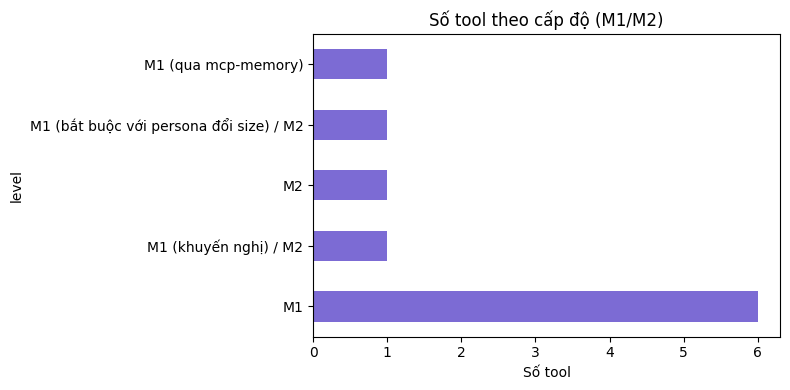

In [3]:
ax = tools_df["level"].value_counts().plot(kind="barh", color="#7c6bd4")
ax.set_title("Số tool theo cấp độ (M1/M2)")
ax.set_xlabel("Số tool")
plt.tight_layout(); plt.show()

## 2. `products.json` — catalog theo ngành hàng

In [4]:
products = load_json("products.json")["products"]
prod_df = pd.DataFrame([{
    "sku": p["sku"], "category": p["category"], "brand": p["brand"],
    "list_price_vnd": p["list_price_vnd"], "n_variants": len(p.get("variants", [])),
    "stock": p.get("stock", 0), "has_successor": bool(p.get("successor_sku")),
} for p in products])

cat_summary = prod_df.groupby("category").agg(
    n_products=("sku", "count"), n_variants=("n_variants", "sum"),
    avg_price_vnd=("list_price_vnd", "mean"), total_stock=("stock", "sum"),
).sort_values("n_products", ascending=False)
display(cat_summary)
print(f"Tổng SKU cha: {len(prod_df)}  |  Tổng biến thể (variants): {prod_df['n_variants'].sum()}")
print(f"SKU có successor_sku (đã ngừng bán, có SKU thay thế): {prod_df['has_successor'].sum()}")

,n_products,n_variants,avg_price_vnd,total_stock
category,,,,
me-be,10,0,3312800.0,148
gia-dung/may-loc-khong-khi,8,0,4941250.0,120
thoi-trang/giay,5,72,1390000.0,288
gia-dung/phu-kien,4,0,665000.0,210
gia-dung/quat,3,0,1610000.0,60
gia-dung/may-loc-nuoc,3,0,5390000.0,37
gia-dung/noi-chien,3,0,2490000.0,52
thoi-trang/ao-khoac,2,24,1090000.0,148
gia-dung/combo,1,0,6390000.0,6


Tổng SKU cha: 40  |  Tổng biến thể (variants): 96
SKU có successor_sku (đã ngừng bán, có SKU thay thế): 0


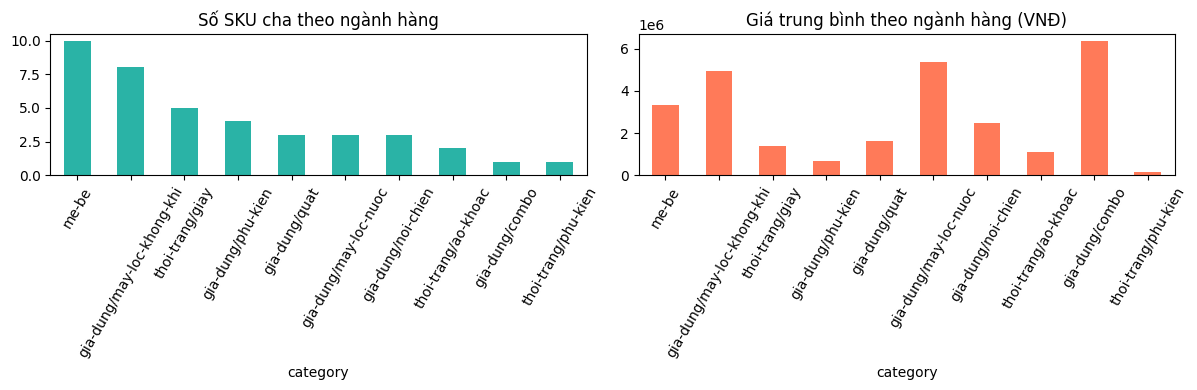

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cat_summary["n_products"].plot(kind="bar", ax=axes[0], color="#2ab3a6")
axes[0].set_title("Số SKU cha theo ngành hàng"); axes[0].tick_params(axis="x", rotation=60)
cat_summary["avg_price_vnd"].plot(kind="bar", ax=axes[1], color="#ff7a59")
axes[1].set_title("Giá trung bình theo ngành hàng (VNĐ)"); axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 3. `promotions.json` — loại khuyến mãi & điều kiện

In [6]:
promos = load_json("promotions.json")["promotions"]
promo_df = pd.DataFrame([{
    "promo_code": p["promo_code"], "type": p["type"], "stackable": p.get("stackable", False),
    "has_conditions": bool(p.get("conditions")),
    "condition_keys": list(p.get("conditions", {}).keys()),
    "applies_to_category": any(str(a).startswith("category:") for a in p["applies_to"]),
    "start": p["start"], "end": p["end"],
} for p in promos])
display(promo_df)

print(promo_df["type"].value_counts())
print(f"Khuyến mãi có điều kiện đặc biệt: {promo_df['has_conditions'].sum()} / {len(promo_df)}")
print(f"Khuyến mãi stackable (cộng dồn được): {promo_df['stackable'].sum()} / {len(promo_df)}")
all_conditions = [c for keys in promo_df["condition_keys"] for c in keys]
print("Các loại điều kiện xuất hiện:", pd.Series(all_conditions).value_counts().to_dict())

,promo_code,type,stackable,has_conditions,condition_keys,applies_to_category,start,end
0,GIFT-FILTER,gift,False,False,[],False,2026-09-25,2026-10-22
1,AIR-OCT,fixed,False,False,[],False,2026-10-05,2026-10-30
2,XM-COMBO,gift,False,False,[],False,2026-10-10,2026-11-14
3,RUN-10,percent,False,True,"[exclude_variant_size, once_per_customer]",False,2026-10-12,2026-10-25
4,AIR-2ND-50,percent_second_item,False,True,[min_qty],True,2026-10-05,2026-11-04
5,NAM-SHIP0,freeship,True,True,[region],True,2026-10-08,2026-11-05
6,TRADE-IN-AP,fixed,False,True,[requires_owned_sku],False,2026-09-15,2026-12-14
7,MOM-FREESHIP,freeship,True,False,[],True,2026-09-15,2026-11-29
8,COD-0,freecod,True,False,[],False,2026-08-16,2026-12-14
9,AP-SEP,fixed,False,False,[],False,2026-08-31,2026-09-30


type
gift                   3
fixed                  3
percent                3
freeship               2
percent_second_item    1
freecod                1
Name: count, dtype: int64
Khuyến mãi có điều kiện đặc biệt: 4 / 13
Khuyến mãi stackable (cộng dồn được): 4 / 13
Các loại điều kiện xuất hiện: {'exclude_variant_size': 1, 'once_per_customer': 1, 'min_qty': 1, 'region': 1, 'requires_owned_sku': 1}


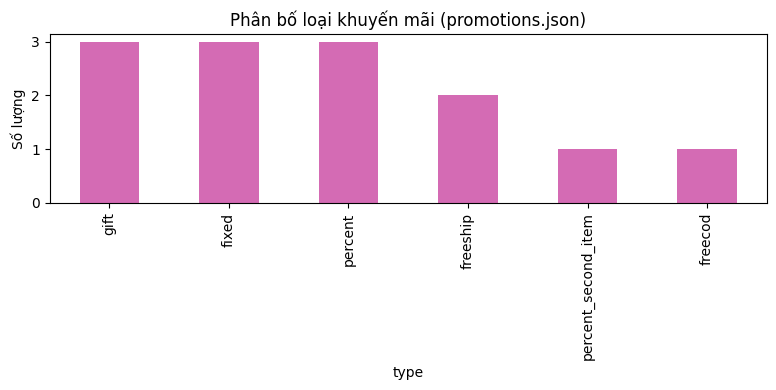

In [7]:
promo_df["type"].value_counts().plot(kind="bar", color="#d46bb4")
plt.title("Phân bố loại khuyến mãi (promotions.json)"); plt.ylabel("Số lượng")
plt.tight_layout(); plt.show()

## 4. `inventory_timeline.json` — tồn kho biến động theo ngày

In [8]:
inv = load_json("inventory_timeline.json")
inv_df = pd.DataFrame(inv["events"])
display(inv_df)
print(f"Ngày tham chiếu (reference_date): {inv['reference_date']}")
print(f"Số SKU có timeline: {inv_df['sku'].nunique()}  |  Tổng số sự kiện: {len(inv_df)}")
print(f"Quy tắc: {inv['rule']}")

,sku,date,qty,note
0,SKU-SN-RUN2-41-DEN,2026-10-15,3,tồn tại ngày tham chiếu
1,SKU-SN-RUN2-41-DEN,2026-10-17,0,hết hàng — kịch bản khách gọi lại size 41 hết
2,SKU-SN-RUN2-41-DEN,2026-10-24,12,nhập lại
3,SKU-AP-PRO,2026-10-15,5,NaN
4,SKU-AP-PRO,2026-10-18,0,hết hàng tạm thời
5,SKU-AP-PRO,2026-10-21,8,NaN
6,SKU-MB-STR1,2026-10-15,2,NaN
7,SKU-MB-STR1,2026-10-25,0,hết hàng khi khách quyết sau 10 ngày
8,SKU-XM-4P,2026-10-15,0,"đang hết, dự kiến về"
9,SKU-XM-4P,2026-10-19,20,NaN


Ngày tham chiếu (reference_date): 2026-10-15
Số SKU có timeline: 6  |  Tổng số sự kiện: 12
Quy tắc: qty có hiệu lực từ 'date' đến bản ghi kế tiếp của cùng sku; sku không có trong timeline dùng stock tĩnh trong products.json


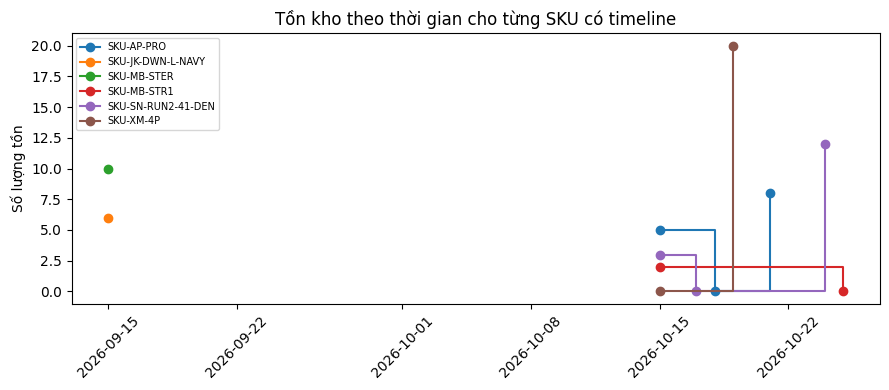

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
for sku, g in inv_df.groupby("sku"):
    g = g.sort_values("date")
    ax.step(pd.to_datetime(g["date"]), g["qty"], where="post", marker="o", label=sku)
ax.set_title("Tồn kho theo thời gian cho từng SKU có timeline")
ax.set_ylabel("Số lượng tồn"); ax.legend(fontsize=7, loc="upper left")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 5. `crm_seed.json` — khách hàng & ca khó sẵn có

In [10]:
crm = load_json("crm_seed.json")
cust = crm["customers"]
cust_df = pd.DataFrame([{
    "customer_id": c["customer_id"], "region": c.get("region"),
    "has_sessions": bool(c.get("sessions")), "has_orders": bool(c.get("orders")),
    "shared_phone_with": c.get("shared_phone_with"),
} for c in cust])

display(cust_df["region"].value_counts().rename("Số khách theo vùng miền"))
print(f"Tổng khách: {len(cust_df)}")
print(f"Khách có session cũ (phục vụ ca TTL/khách quay lại): {cust_df['has_sessions'].sum()}")
print(f"Khách có đơn hàng sẵn (phục vụ ca theo dõi đơn): {cust_df['has_orders'].sum()}")
print(f"Khách dùng chung SĐT (phục vụ ca PII): {cust_df['shared_phone_with'].notna().sum()}")
print("\nGhi chú gốc trong file:", crm.get("notes"))

region
trung    18
nam      17
bac      15
Name: Số khách theo vùng miền, dtype: int64

Tổng khách: 50
Khách có session cũ (phục vụ ca TTL/khách quay lại): 3
Khách có đơn hàng sẵn (phục vụ ca theo dõi đơn): 2
Khách dùng chung SĐT (phục vụ ca PII): 2

Ghi chú gốc trong file: customers[30..34] có lịch sử/đặc thù dùng cho ca khó: sessions cũ >6 tháng (TTL), đơn đang giao, 2 người chung SĐT


## 6. Các schema object — trường bắt buộc (`required`)

In [11]:
schema_files = ["call_brief_schema.json", "handoff_brief_schema.json", "trace_log_schema.json"]
for name in schema_files:
    sch = load_json(name)
    print(f"### {sch.get('title', name)}  ({name})")
    print("required:", sch.get("required"))
    print("tổng số field properties:", len(sch.get("properties", {})))
    print()

### CallBrief  (call_brief_schema.json)
required: ['customer_phone', 'is_returning', 'n_previous_sessions', 'last_session', 'products_advised', 'open_blockers', 'must_not_ask', 'suggested_opening', 'generated_at', 'latency_ms']
tổng số field properties: 18

### HandoffBrief  (handoff_brief_schema.json)
required: ['customer_phone', 'customer_name', 'escalation_reason', 'conversation_summary', 'product_advised', 'price_quoted_vnd', 'open_questions', 'next_action', 'generated_at']
tổng số field properties: 16

### AgentTraceLine  (trace_log_schema.json)
required: ['run_id', 'config', 'scenario_id', 'call', 'turn', 'customer_text', 'agent_text', 'questions', 'claims', 'tool_calls', 'latency']
tổng số field properties: 15



## 7. `scenario_format.md` — khung kịch bản test

(hiển thị nguyên văn để tiện đối chiếu khi code parser/scenario loader)

In [12]:
with open(os.path.join(UPLOADS_DIR, "scenario_format.md"), encoding="utf-8") as f:
    content = f.read()
from IPython.display import Markdown, display as ipy_display
ipy_display(Markdown(content))

# Định dạng kịch bản test (mở rộng Phụ lục B)

Mỗi file `SC-xx.json`: `scenario_id, level (M1|M2), persona, hard_case, customer_phone, customer_name, honorific, notes, calls{call_1..call_3}`.

Trường trong mỗi `call_n`:
| Trường | Ý nghĩa | Dùng cho |
|---|---|---|
| `channel`, `channel_identity` | hotline / chat_fanpage / zalo_oa + định danh kênh | identity resolution |
| `call_date` hoặc `days_later` | ngày của cuộc gọi (mặc định reference_date 2026-10-15 + cộng dồn days_later) | KM hết hạn, tồn kho theo ngày, TTL |
| `customer_turns` | lượt khách viết sẵn (deterministic) | chấm chéo |
| `customer_turns_asr` + `input_mode` | bản lỗi ASR / teencode — **hệ thống phải nhận bản này** nếu có | chuẩn hóa tiếng Việt |
| `seed_history` | phiên cũ (từ CRM) cần nạp trước khi gọi | TTL, khách cũ |
| `facts_established` | fact khách cung cấp trong call này (ground truth để ghi nhớ) | CCR của call sau |
| `must_carry_over` | slot bắt buộc dùng đúng ở call này | CCR |
| `must_not_ask` | slot không được hỏi mở | RQR |
| `success_if` | điều kiện Task Success (xem dưới) | TSR |
| `ground_truth_facts` | sự thật để đối chiếu claim | HR |
| `memory_expectation` | trạng thái bộ nhớ kỳ vọng sau call (giá trị mới, giá trị bị supersede, hồ sơ không được ghi nhầm) | memory_checks (sàng lọc) + chấm tay |
| `expected_outcome` | hen_goi_lai / chot_don / chuyen_may / tu_choi | over-escalation |

`success_if` hỗ trợ: `tool_called` (+ `args_match` ⊆ args; `null` = không cần tool), `also_ordered`, `total_match_vnd`, `brief_must_contain`, `must_say_any` (≥1 cụm xuất hiện trong lời agent), `agent_must_say` (cụm "không có thông tin"), `must_not_call_tools`, `forbidden_claims` ([{field,value}] hoặc chuỗi; value `"*any*"` = mọi giá trị), `trace_must_not_match` (regex trên agent_text + memory_writes + tool args → PII/nội bộ), `max_agent_questions`.

Ngày của call_n = `call_date` nếu có, nếu không = ngày call trước + `days_later` (call_1 mặc định 2026-10-15). Tool mock phải nhận ngày này qua `on`.


## 8. Đối chiếu: bộ `dev_dataset_v2/scenarios` đã tự sinh

Phần này đọc `scenarios_all.json` (138 kịch bản tự sinh) để kiểm nhanh độ phủ persona/ca khó,
mức dùng tool chính thức so với tool phụ (`additional_tools_used`), và phân bố level M1/M2.

In [13]:
scenarios = load_json("scenarios_all.json", base=os.path.join(DATASET_DIR, "scenarios"))
sc_df = pd.DataFrame([{
    "scenario_id": s["scenario_id"], "level": s["level"], "persona": s["persona"],
    "hard_case": s["hard_case"], "n_calls": len(s["calls"]),
    "n_additional_tools": len(s.get("additional_tools_used", [])),
    "channels": sorted({c.get("channel") for c in s["calls"].values()}),
} for s in scenarios])

display(sc_df.head())
print(f"Tổng số kịch bản: {len(sc_df)}")
print(sc_df["level"].value_counts())
print(f"\nScenarios dùng >=1 tool phụ (ngoài tools_schema.json): {(sc_df['n_additional_tools'] > 0).sum()} / {len(sc_df)}")

,scenario_id,level,persona,hard_case,n_calls,n_additional_tools,channels
0,SC-001,M1,khach_do_du_hoi_nguoi_nha,NaN,2,0,[hotline]
1,SC-002,M1,khach_do_du_hoi_nguoi_nha,NaN,2,0,[hotline]
2,SC-003,M1,khach_do_du_hoi_nguoi_nha,NaN,2,0,"[chat_fanpage, zalo_oa]"
3,SC-004,M1,khach_do_du_hoi_nguoi_nha,NaN,2,0,"[chat_fanpage, zalo_oa]"
4,SC-005,M1,khach_do_du_hoi_nguoi_nha,NaN,2,0,"[chat_fanpage, hotline]"


Tổng số kịch bản: 138
level
M1    127
M2     11
Name: count, dtype: int64

Scenarios dùng >=1 tool phụ (ngoài tools_schema.json): 8 / 138


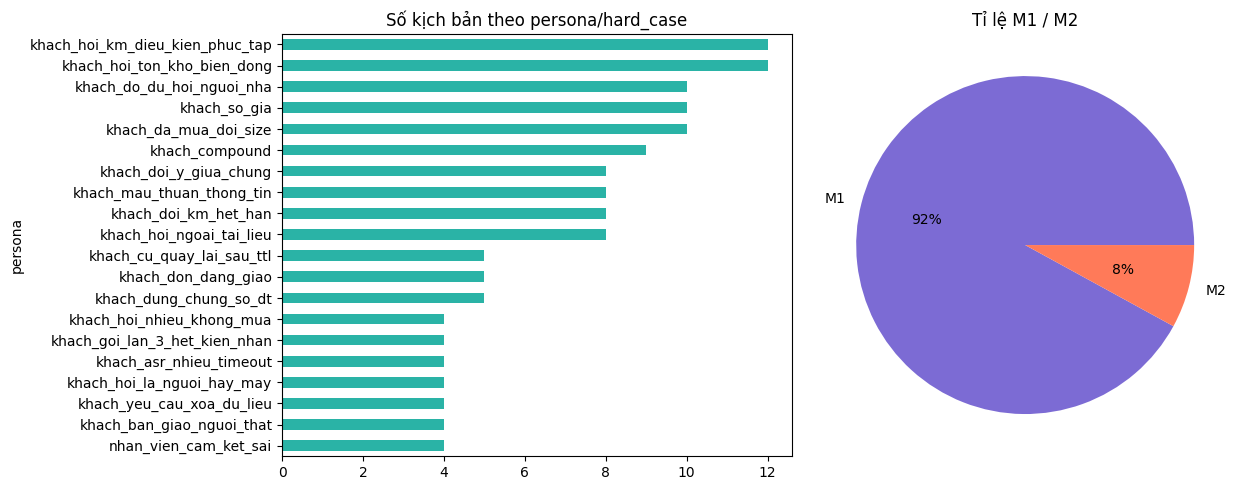

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc_df["persona"].value_counts().plot(kind="barh", ax=axes[0], color="#2ab3a6")
axes[0].set_title("Số kịch bản theo persona/hard_case"); axes[0].invert_yaxis()
sc_df["level"].value_counts().plot(kind="pie", ax=axes[1], autopct="%1.0f%%",
                                    colors=["#7c6bd4", "#ff7a59"])
axes[1].set_title("Tỉ lệ M1 / M2"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

In [15]:
# Tool nào được dùng nhiều nhất trong success_if (tool_called/tool_not_called), đối chiếu tools_schema.json
official_tools = {t["name"] for t in tools}
tool_usage = {}
for s in scenarios:
    for call in s["calls"].values():
        succ = call.get("success_if")
        if not succ:
            continue
        checks = succ.get("all_of", [succ])
        for chk in checks:
            for key in ("tool_called", "tool_not_called"):
                tname = chk.get(key) if chk else None
                if tname:
                    tool_usage[tname] = tool_usage.get(tname, 0) + 1

tool_usage_df = pd.DataFrame([
    {"tool": k, "count": v, "official": k in official_tools} for k, v in tool_usage.items()
]).sort_values("count", ascending=False)
display(tool_usage_df)
print(f"Tool KHÔNG nằm trong tools_schema.json (tool phụ): {(~tool_usage_df['official']).sum()} / {len(tool_usage_df)}")

,tool,count,official
0,order.create,40,True
1,order.update,21,True
5,inventory.check,12,True
3,memory.read,8,False
6,memory.write,7,False
4,order.status,5,True
2,kb.search,4,False
7,handoff.transfer,4,True
8,copilot_alert,4,False


Tool KHÔNG nằm trong tools_schema.json (tool phụ): 4 / 9


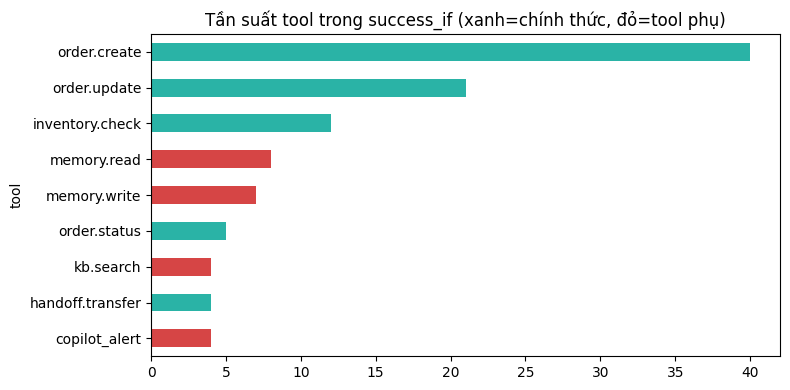

In [16]:
colors = tool_usage_df["official"].map({True: "#2ab3a6", False: "#d64545"})
ax = tool_usage_df.set_index("tool")["count"].plot(kind="barh", color=colors)
ax.invert_yaxis()
ax.set_title("Tần suất tool trong success_if (xanh=chính thức, đỏ=tool phụ)")
plt.tight_layout(); plt.show()

## 9. Tổng kết nhanh

Bảng dưới gộp các con số chính để bạn đối chiếu một lượt trước khi bắt tay code agent/harness chấm.

In [17]:
summary = pd.DataFrame([
    {"Hạng mục": "Tool chính thức (tools_schema.json)", "Số lượng": len(tools_df)},
    {"Hạng mục": "SKU cha trong catalog", "Số lượng": len(prod_df)},
    {"Hạng mục": "Biến thể SKU (variants)", "Số lượng": int(prod_df["n_variants"].sum())},
    {"Hạng mục": "Khuyến mãi", "Số lượng": len(promo_df)},
    {"Hạng mục": "Khuyến mãi có điều kiện đặc biệt", "Số lượng": int(promo_df["has_conditions"].sum())},
    {"Hạng mục": "SKU có tồn kho biến động theo ngày", "Số lượng": int(inv_df["sku"].nunique())},
    {"Hạng mục": "Khách hàng trong crm_seed.json", "Số lượng": len(cust_df)},
    {"Hạng mục": "Kịch bản dev đã tự sinh (scenarios_all.json)", "Số lượng": len(sc_df)},
    {"Hạng mục": "Kịch bản dev dùng tool phụ (ngoài schema)", "Số lượng": int((sc_df['n_additional_tools'] > 0).sum())},
])
display(summary)

,Hạng mục,Số lượng
0,Tool chính thức (tools_schema.json),10
1,SKU cha trong catalog,40
2,Biến thể SKU (variants),96
3,Khuyến mãi,13
4,Khuyến mãi có điều kiện đặc biệt,4
5,SKU có tồn kho biến động theo ngày,6
6,Khách hàng trong crm_seed.json,50
7,Kịch bản dev đã tự sinh (scenarios_all.json),138
8,Kịch bản dev dùng tool phụ (ngoài schema),8
